# 22. Generate Parentheses
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Combinations](README.md) · **LeetCode:** https://leetcode.com/problems/generate-parentheses/

## 💡 Concepts

**Core concept(s):** **Backtracking with counters as the constraint** — build the string one character at a time, and only add a character that keeps the prefix valid.

> NeetCode files this problem under **Stack**, because checking a parenthesis string is a stack/counter job. Generating *all* valid strings, though, is a backtracking build: one choice (`(` or `)`) per position, with two rules that prune every invalid branch. That is why it sits in the [Combinations](README.md) pattern here.

**Why it applies here:**
- An answer is a string of length `2n`; each position is `(` or `)`. That is a binary tree of choices.
- A prefix is still completable **iff** it never closes more than it opened and never opens more than `n`.
- So two counters decide which branches exist: no invalid string is ever built, and no filtering is needed afterwards.

**Key intuition:**
- Add `(` while `open < n`.
- Add `)` only while `close < open` (there is an unmatched `(` to close).
- When the string has length `2n`, it is valid by construction: record it.

---

### 📚 What is a Stack (and why a counter is enough)?
- A **stack** is last-in, first-out: you push on top and pop from the top.
- Checking brackets: push on `(`, pop on `)`. The string is valid if you never pop an empty stack and the stack ends empty.
- With **one** bracket type every stack entry is the same `(`, so the stack is fully described by its size: a single counter `balance` (`+1` on `(`, `-1` on `)`).
- **In Python:** a `list` with `append`/`pop`, or just an `int` here.

### 📚 What is Recursion?
- A function that calls itself on a smaller problem, with a **base case** that stops it.
- Here the base case is "the string has `2n` characters"; the call stack is `2n` calls deep.

### 📚 What is Backtracking?
- Build the answer in a shared `path`: **choose** (`append` a bracket), **explore** (recurse), **un-choose** (`pop`).
- **Pruning** = not making a choice that can't lead to an answer. Here the counter rules prune *every* dead branch, so every leaf is an answer.
- **Complexity:** proportional to the number of answers, the `n`-th **Catalan number** `C(n) ≈ 4^n / (n^1.5 · √π)` (1, 2, 5, 14, 42, 132, ...).
- **In Python:** `path` as a `list` of characters, `"".join(path)` at a leaf.

---

**Prerequisite knowledge:**
- [Valid Parentheses](https://leetcode.com/problems/valid-parentheses/) (the balance check).
- The choose / explore / undo template from [Letter Combinations of a Phone Number](letter_combinations_of_a_phone_number.ipynb).

## 📝 Problem

Given `n` pairs of parentheses, return all combinations of **well-formed** (balanced) parentheses of length `2n`, in any order.

**Example 1**
```
n = 3  ->  ["((()))", "(()())", "(())()", "()(())", "()()()"]
```

**Example 2**
```
n = 1  ->  ["()"]
```

**Constraints:** `1 <= n <= 8`.

> Two approaches: a brute force that generates all `2^(2n)` bracket strings and keeps the balanced ones, and backtracking that only ever builds valid prefixes (the [Combinations](README.md) template with open/close counts).

In [1]:
from typing import List

### Approach 1 — Brute Force: every string of `(` and `)`, then filter

**Idea:**
1. Generate every string of length `2n` over `{(, )}` by trying both characters at every position.
2. At each full-length string, run the balance check: `balance` must never go negative and must end at 0.
3. Keep the strings that pass.

**Time complexity:** `O(2^(2n) · n)` = `O(4^n · n)` — `4^n` strings, each checked in `O(n)`.

**Space complexity:** `O(n)` — the recursion depth and `path` are `2n`; output aside.

In [2]:
def generate_parenthesis_brute(n: int) -> List[str]:
    out = []
    def valid(s):
        balance = 0
        for c in s:
            balance += 1 if c == "(" else -1
            if balance < 0:
                return False               # closed a bracket that was never opened
        return balance == 0                # every opened bracket was closed
    def gen(path):
        if len(path) == 2 * n:
            s = "".join(path)
            if valid(s):                   # filter AFTER building the whole string
                out.append(s)
            return
        for c in "()":                     # no rules: both characters at every position
            path.append(c)
            gen(path)
            path.pop()
    gen([])
    return out

### Approach 2 — Backtracking with open/close counts (optimal · pattern template)

**Idea:** the [Combinations](README.md) template, where the choices at each step are `(` and `)`, and the counters are the pruning rule.
1. `backtrack(open_, close)`: if the path has `2n` characters, record it.
2. If `open_ < n`, choose `(`, recurse with `open_ + 1`, pop.
3. If `close < open_`, choose `)`, recurse with `close + 1`, pop.

**Time complexity:** `O(4^n / √n)` — the number of valid strings is the Catalan number `C(n) ~ 4^n / n^1.5`, each one costs `O(n)` to build and join, and every node of the tree lies on the path to at least one answer (no dead branches).

**Space complexity:** `O(n)` — the recursion depth and `path` are `2n`; output aside.

In [3]:
def generate_parenthesis_backtrack(n: int) -> List[str]:
    out, path = [], []
    def backtrack(open_, close):           # how many '(' and ')' are in path so far
        if len(path) == 2 * n:
            out.append("".join(path))      # valid by construction: no check needed
            return
        if open_ < n:                      # an opening bracket is still available
            path.append("(")
            backtrack(open_ + 1, close)
            path.pop()
        if close < open_:                  # there is an unmatched '(' to close
            path.append(")")
            backtrack(open_, close + 1)
            path.pop()
    backtrack(0, 0)
    return out

In [4]:
# Correctness check
tests = [
    (1, ["()"]),                                                   # LeetCode example 2
    (2, ["(())", "()()"]),
    (3, ["((()))", "(()())", "(())()", "()(())", "()()()"]),       # LeetCode example 1
]
for n, exp in tests:
    a, b = generate_parenthesis_brute(n), generate_parenthesis_backtrack(n)
    print(f"n={n} -> {b}")
    assert sorted(a) == sorted(b) == sorted(exp), f"mismatch on n={n}"

# The counts must be the Catalan numbers, and both approaches must agree
catalan = [1, 1, 2, 5, 14, 42, 132, 429, 1430]
for n in range(1, 9):
    b = generate_parenthesis_backtrack(n)
    assert len(b) == len(set(b)) == catalan[n], n
    if n <= 6:
        assert sorted(generate_parenthesis_brute(n)) == sorted(b), n
print("n = 1..8: counts are the Catalan numbers 1, 2, 5, 14, 42, 132, 429, 1430; brute agrees for n <= 6")

print("\nAll tests passed")

n=1 -> ['()']
n=2 -> ['(())', '()()']
n=3 -> ['((()))', '(()())', '(())()', '()(())', '()()()']
n = 1..8: counts are the Catalan numbers 1, 2, 5, 14, 42, 132, 429, 1430; brute agrees for n <= 6

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. Both approaches are exponential in `n`, so doubling `n` is impossible to time; we grow `n` by **+1 pair** per step instead. The ratio column is **per +1 pair, not per doubling** (ignore the helper's doubling footer). The input `n` is the whole input, so it is also the worst case.

| Approach | Expected ratio per +1 pair |
|----------|----------------------------|
| Brute force `O(4^n · n)` | ≈ **4–4.5×**: 4× more strings, each one character pair longer (`4 · (n+1)/n`) |
| Backtracking `O(4^n / √n)` | ≈ **3.3–3.8×**: the Catalan ratio `C(n)/C(n-1) = 2(2n-1)/(n+1)` (3.25 for 6 → 7, 3.45 for 9 → 10) times the `(n+1)/n` growth of each string. These runs take a few milliseconds at most, so individual ratios wobble. |

The gap between the two rows also widens by roughly `n^1.5` — the brute force builds `4^n` strings to keep `C(n)` of them.

answers (Catalan): [132, 429, 1430, 4862, 16796]

brute: all 4^n strings + filter
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       1.03 |           n/a
        7 |       4.28 |         4.15x
        8 |      18.01 |         4.21x


        9 |      74.84 |         4.15x


       10 |     331.14 |         4.42x

backtracking with counts
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       0.04 |           n/a
        7 |       0.14 |         3.26x
        8 |       0.46 |         3.38x
        9 |       1.64 |         3.59x
       10 |       5.51 |         3.37x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


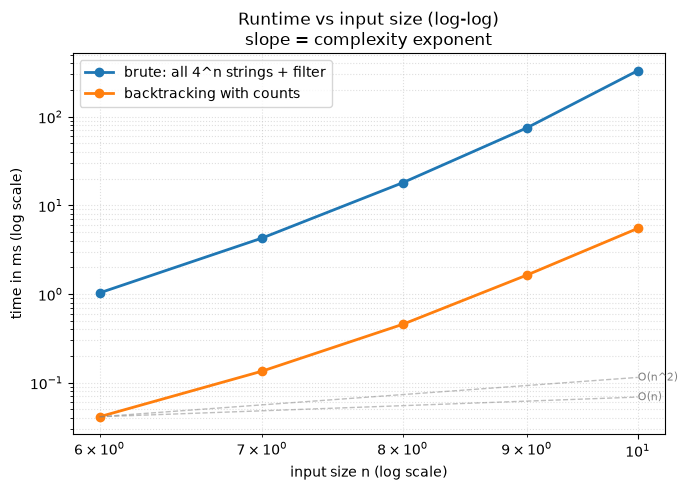

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (n,)                        # n pairs: the input is just the number
solutions = {
    "brute: all 4^n strings + filter": generate_parenthesis_brute,
    "backtracking with counts": generate_parenthesis_backtrack,
}
sizes = [6, 7, 8, 9, 10]               # pairs, +1 per step

print("answers (Catalan):", [len(generate_parenthesis_backtrack(n)) for n in sizes])
_ = benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Combinations](README.md) — the choose/explore/undo template with two choices per position (`(` / `)`), where the open/close counts decide which choices are allowed.
- **Prune with an invariant, don't filter at the end:** `open_ < n` and `close < open_` keep every prefix completable, so every leaf is an answer.
- **One bracket type → a counter replaces the stack:** the stack would only ever hold `(`, so its size is all that matters.
- **Signal:** "generate all valid / well-formed ...", "all combinations of n pairs", a validity rule that can be checked on a prefix.
- **Related problems:** Valid Parentheses (the check), Letter Combinations of a Phone Number (same tree without a rule), Remove Invalid Parentheses, Palindrome Partitioning (prune by a prefix rule).
- **Common pitfalls:**
  1. Allowing `)` when `close < n` instead of `close < open_` — builds `())(`-style invalid strings.
  2. Checking validity only at the end — correct but `4^n`, the brute force.
  3. Forgetting `path.pop()` after each branch, or using one mutable string without undoing.